# CASME Spotting Graph Comparison

Grafik perbandingan hasil spotting dengan ground truth CAS(ME)3 part A (`spNO.1 / a`).

In [17]:
import re
import sys
from pathlib import Path

import cv2
import dlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from apex import ApexPhase, ApexSmoother
from features_extraction.poc import POC
from features_extraction.quadran import Quadran
from features_extraction.vektor import Vektor


In [18]:
ROOT_DIR = PROJECT_ROOT / 'dataset' / 'casme'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'casme_spotting_graph_clean'
PLOTS_DIR = OUTPUT_DIR / 'plots'
PREDICTOR_PATH = Path('./models/shape_predictor_68_face_landmarks.dat')
GT_XLS_PATH = Path('/home/ryuko/Downloads/CAS(ME)3_part_A_v1(1).xls')

BLOCK_SIZE = 7
PADDING_X = 6
PADDING_Y = 8
TOP_K_APEX = 10
MIN_PHASE_DURATION = 2
DISTANCE_THRESHOLD = 1
PROMINENCE_THRESHOLD = 0.005
CUTOFF_RATIO = 0.3

REGIONS = {
    'mata_alis_kanan': list(range(42, 48)) + list(range(22, 27)),
    'mata_alis_kiri': list(range(36, 42)) + list(range(17, 22)),
    'mulut': list(range(48, 68)),
}

TARGET_SIZE = {
    'mata_alis_kanan': (64, 40),
    'mata_alis_kiri': (64, 40),
    'mulut': (70, 35),
}

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'ROOT_DIR = {ROOT_DIR}')
print(f'PLOTS_DIR = {PLOTS_DIR}')
print(f'ROI = {list(REGIONS)}')


ROOT_DIR = /home/ryuko/skripsi/Skripsi/Convat-1st/dataset/casme
PLOTS_DIR = /home/ryuko/skripsi/Skripsi/Convat-1st/output/casme_spotting_graph_clean/plots
ROI = ['mata_alis_kanan', 'mata_alis_kiri', 'mulut']


In [19]:
def natural_sort_key(value: str):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', value)]


def load_ground_truth() -> pd.DataFrame:
    return pd.DataFrame([
        {'subject': 'spNO.1', 'clip': 'a', 'onset': 355, 'apex': 359, 'offset': 360, 'au': '5', 'type': 'Micro-expression', 'emotion': 'II'},
    ])


gt_df = load_ground_truth()
gt_df


,subject,clip,onset,apex,offset,au,type,emotion
0,spNO.1,a,355,359,360,5,Micro-expression,II


In [20]:
def extract_region(image: np.ndarray, landmarks, indices: list[int]) -> np.ndarray:
    pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in indices]
    xs, ys = zip(*pts)
    left = max(0, min(xs) - PADDING_X)
    top = max(0, min(ys) - PADDING_Y)
    right = min(image.shape[1], max(xs) + PADDING_X)
    bottom = min(image.shape[0], max(ys) + PADDING_Y)
    return image[top:bottom, left:right]


def detect_landmarks(gray: np.ndarray, detector, predictor):
    faces = detector(gray)
    if len(faces) > 0:
        return predictor(gray, faces[0])
    return None


def compute_frame_magnitudes(prev_gray, prev_lm, curr_gray, curr_lm) -> dict[str, float]:
    roi_values = {}
    for region_name, lm_indices in REGIONS.items():
        try:
            roi_prev = extract_region(prev_gray, prev_lm, lm_indices)
            roi_curr = extract_region(curr_gray, curr_lm, lm_indices)
            if roi_prev.size == 0 or roi_curr.size == 0:
                roi_values[region_name] = 0.0
                continue
            roi_prev = cv2.resize(roi_prev, TARGET_SIZE[region_name])
            roi_curr = cv2.resize(roi_curr, TARGET_SIZE[region_name])
            poc = POC(roi_prev, roi_curr, BLOCK_SIZE)
            vec = Vektor(poc.getPOC(), BLOCK_SIZE)
            quad_data = Quadran(vec.getVektor()).getQuadran()
            magnitudes = [float(block[4]) for block in quad_data]
            roi_values[region_name] = float(np.mean(magnitudes)) if magnitudes else 0.0
        except Exception:
            roi_values[region_name] = 0.0
    return roi_values


def build_signal(frame_paths: list[Path]) -> tuple[list[float], pd.DataFrame]:
    detector = dlib.get_frontal_face_detector()
    predictor = dlib.shape_predictor(str(PREDICTOR_PATH))
    grays = [cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) for path in frame_paths]
    grays = [gray for gray in grays if gray is not None]
    raw_signal = []
    rows = []
    prev_gray = grays[0]
    prev_lm = detect_landmarks(prev_gray, detector, predictor)
    for i, curr_gray in enumerate(grays[1:], start=1):
        curr_lm = detect_landmarks(curr_gray, detector, predictor)
        if prev_lm is not None and curr_lm is not None:
            roi_values = compute_frame_magnitudes(prev_gray, prev_lm, curr_gray, curr_lm)
        else:
            roi_values = {region: 0.0 for region in REGIONS}
        raw_value = float(np.mean(list(roi_values.values())))
        raw_signal.append(raw_value)
        rows.append({'frame_index': i, **roi_values, 'raw_magnitude': raw_value})
        prev_gray = curr_gray
        prev_lm = curr_lm
    return raw_signal, pd.DataFrame(rows)


In [21]:
if not ROOT_DIR.exists():
    raise FileNotFoundError(f'CASME root not found: {ROOT_DIR}')
if not PREDICTOR_PATH.exists():
    raise FileNotFoundError(f'Predictor not found: {PREDICTOR_PATH}')

frame_paths = sorted(
    [p for p in ROOT_DIR.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}],
    key=lambda p: natural_sort_key(p.name),
)
if len(frame_paths) < 3:
    raise ValueError(f'Too few frames: {len(frame_paths)}')

raw_signal, signal_df = build_signal(frame_paths)
smooth_signal = ApexSmoother.smooth(raw_signal)
signal_df['smoothed_magnitude'] = smooth_signal
print(f'frames={len(frame_paths)} signal={len(smooth_signal)}')
signal_df.head()


frames=836 signal=835


,frame_index,mata_alis_kanan,mata_alis_kiri,mulut,raw_magnitude,smoothed_magnitude
0,1,0.329511,0.088889,0.71806,0.378820,0.525756
1,2,0.813244,0.467111,0.48434,0.588232,0.512984
2,3,0.868911,0.259022,0.49368,0.540538,0.500432
3,4,0.479467,0.894289,0.43100,0.601585,0.488448
4,5,0.916133,0.111111,0.44832,0.491855,0.477335


In [22]:
phase_detector = ApexPhase(
    distance_threshold=DISTANCE_THRESHOLD,
    prominence_threshold=PROMINENCE_THRESHOLD,
    cutoff_ratio=CUTOFF_RATIO,
)

signal_arr = np.asarray(smooth_signal, dtype=float)
threshold = float(signal_arr.mean() + signal_arr.std())
apex_indices = phase_detector.find_top_k_apex(smooth_signal, k=TOP_K_APEX, height=threshold)
phases = phase_detector.find_phase(smooth_signal, apex_indices) if apex_indices else {}

pred_events = []
for event_no, apex_idx in enumerate(apex_indices, start=1):
    phase = phases[apex_idx]
    duration = int(phase['end'] - phase['start'])
    if duration < MIN_PHASE_DURATION:
        continue
    pred_events.append({
        'event_no': event_no,
        'onset': int(phase['start']) + 1,
        'apex': int(apex_idx) + 1,
        'offset': int(phase['end']) + 1,
        'duration': duration,
    })

pred_df = pd.DataFrame(pred_events)
pred_df


,event_no,onset,apex,offset,duration
0,1,15,20,28,13
1,2,30,38,42,12
2,3,47,56,87,40
3,4,317,355,400,83
4,5,432,466,492,60
5,6,533,540,550,17
6,7,564,579,618,54
7,8,625,666,679,54
8,9,703,712,722,19
9,10,803,814,827,24


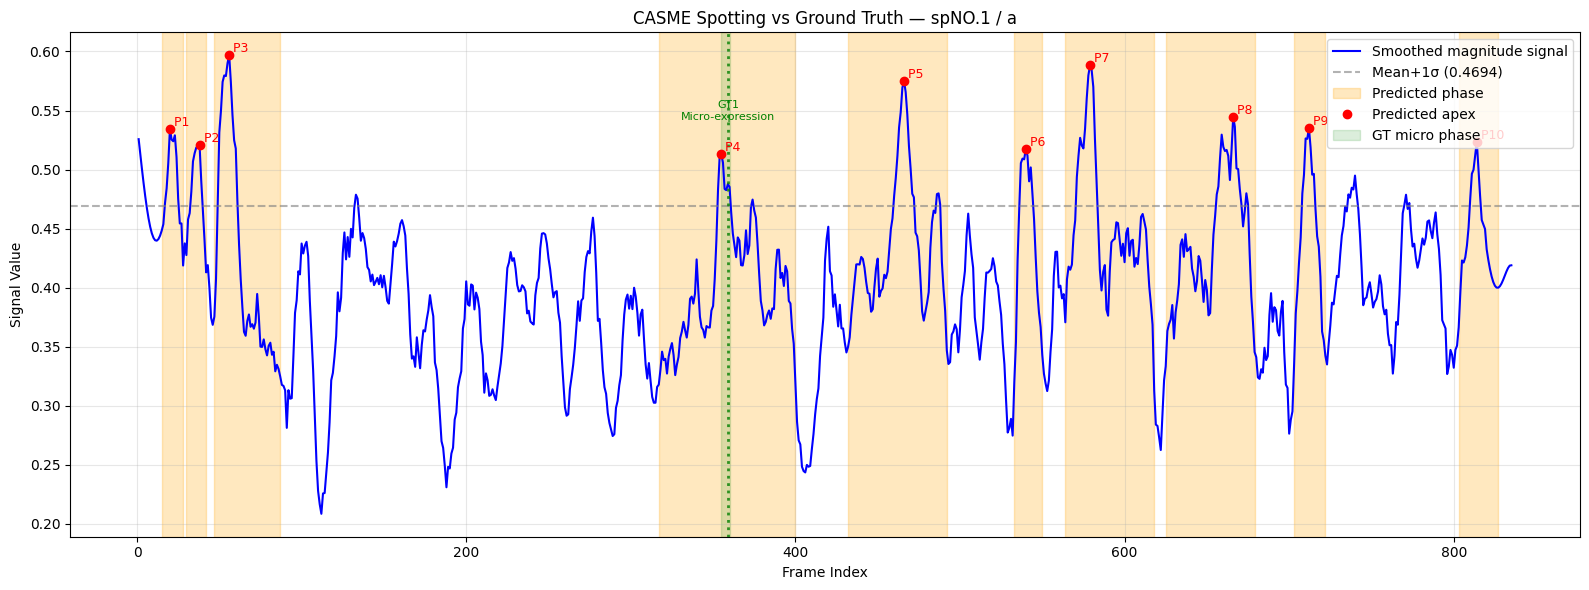

Saved plot: /home/ryuko/skripsi/Skripsi/Convat-1st/output/casme_spotting_graph_clean/plots/casme_spotting_vs_ground_truth.png


In [23]:
out_path = PLOTS_DIR / 'casme_spotting_vs_ground_truth.png'
fig, ax = plt.subplots(figsize=(16, 6))

x = np.arange(1, len(smooth_signal) + 1)
ax.plot(x, smooth_signal, label='Smoothed magnitude signal', color='blue', linewidth=1.5)
ax.axhline(threshold, color='gray', linestyle='--', alpha=0.6, label=f'Mean+1σ ({threshold:.4f})')

for i, event in enumerate(pred_events):
    ax.axvspan(event['onset'], event['offset'], color='orange', alpha=0.25, label='Predicted phase' if i == 0 else '')
    ax.plot(event['apex'], smooth_signal[event['apex'] - 1], 'ro', label='Predicted apex' if i == 0 else '')
    ax.text(event['apex'], smooth_signal[event['apex'] - 1], f" P{event['event_no']}", color='red', fontsize=9, va='bottom')

for i, row in gt_df.iterrows():
    color = 'green' if str(row['type']).lower().startswith('micro') else 'purple'
    label = None
    if color == 'green' and not any(str(gt_df.iloc[j]['type']).lower().startswith('micro') for j in range(i)):
        label = 'GT micro phase'
    if color == 'purple' and not any(not str(gt_df.iloc[j]['type']).lower().startswith('micro') for j in range(i)):
        label = 'GT macro phase'
    ax.axvspan(row['onset'], row['offset'], color=color, alpha=0.14, label=label)
    ax.axvline(row['apex'], color=color, linestyle=':', linewidth=2, alpha=0.8)
    y = ax.get_ylim()[1] * (0.88 - (i % 4) * 0.08)
    ax.text(row['apex'], y, f"GT{i + 1}\n{row['type']}", color=color, fontsize=8, ha='center')

ax.set_title('CASME Spotting vs Ground Truth — spNO.1 / a')
ax.set_xlabel('Frame Index')
ax.set_ylabel('Signal Value')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Saved plot: {out_path}')


In [24]:
comparison_df = pd.concat(
    [
        gt_df.assign(source='ground_truth')[['source', 'type', 'onset', 'apex', 'offset']],
        pred_df.assign(source='predicted', type='spotting')[['source', 'type', 'onset', 'apex', 'offset']],
    ],
    ignore_index=True,
)
comparison_df


,source,type,onset,apex,offset
0,ground_truth,Micro-expression,355,359,360
1,predicted,spotting,15,20,28
2,predicted,spotting,30,38,42
3,predicted,spotting,47,56,87
4,predicted,spotting,317,355,400
5,predicted,spotting,432,466,492
6,predicted,spotting,533,540,550
7,predicted,spotting,564,579,618
8,predicted,spotting,625,666,679
9,predicted,spotting,703,712,722
